### PDF 문서 처리 - 텍스트·표·이미지 추출

PDF에서 추출한 표를 읽기 쉬운 Markdown으로 정리하고, 이미지의 내용을 Gemini로 읽는다. 본문·표·이미지에서 읽은 내용을 구분해 보관한 뒤, 유형에 맞게 RAG용 청크를 만든다.

**PDF 텍스트 추출 → 표·이미지 내용 정리 → 유형별로 구분 → 청킹**

### 환경설정

필요한 패키지를 설치한다.

```bash
pip install pdfplumber==0.11.10
```

In [1]:
import base64
from io import BytesIO
from pathlib import Path
from pprint import pprint

import pdfplumber
from IPython.display import Image, Markdown, display
from langchain_community.document_loaders import PyPDFLoader
from langchain_core.documents import Document
from langchain_core.messages import HumanMessage
from langchain_text_splitters import RecursiveCharacterTextSplitter
from dotenv import load_dotenv
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.output_parsers import StrOutputParser

### PDF 파일 준비

현재 작업 폴더의 `data` 폴더에 있는 `250204_태블릿+PC+품질비교시험_보도자료.pdf`를 사용한다.

In [2]:
PDF_NAME = "250204_태블릿+PC+품질비교시험_보도자료.pdf"

pdf_path = Path("data") / PDF_NAME

if not pdf_path.is_file():
    raise FileNotFoundError(f"PDF 파일을 확인하세요: {pdf_path}")

print(f"PDF 경로: {pdf_path}")

PDF 경로: data\250204_태블릿+PC+품질비교시험_보도자료.pdf


### PDF 텍스트 추출

PDF에서 읽은 1페이지 본문과 제품표의 텍스트를 확인한다.

In [3]:
loader = PyPDFLoader(str(pdf_path))
docs = loader.load()

print(docs[0].page_content)

- 1 -
[태블릿 PC 품질비교 결과]
주용도를 고려해 꼼꼼하게 선택해야
- 영상ㆍ음향 품질, 앱 구동ㆍ펜 필기 성능, 사용가능시간 등에 차이 있어 -
‘태블릿 PC’에 관한 가격·품질 비교정보는 ‘소비자24(www.consumer.go.kr)’ 내 ‘비교공감’란을 
통해 소비자에게 제공될 예정임.
  태블릿 PC는 휴대성이 높고, 기존 종이 재질의 책을 대체하거나 영상 콘텐츠 
시청 용도로 적합해 소비자들의 관심이 높은 품목이지만, 제품 간 품질·성능에 
대한 객관적인 비교정보는 부족한 실정이다.
  이에 한국소비자원(원장 윤수현)이 소비자의 제품 구매·선택을 돕기 위해 
시중에 유통 중인 태블릿 PC 4개 제품의 품질(영상품질, 음향품질, 앱 구동 성능, 
펜 필기 성능, 카메라품질, 사용가능시간 등) ‧제품특성(구성품, 제품 무게, 보유기능 등) 
등을 시험평가했다.
  시험평가 결과 영상품질·음향품질·앱 구동 성능·펜 필기 성능·카메라품질·
사용가능시간 등 주요 성능에서 제품 간 차이가 있었다.
[ 시험평가 대상 제품 ]
구분 브랜드 제품명
(모델명) 화면크기 저장용량 본체가격*[원] 펜 가격*[원]
고가형
삼성 탭 S10+
(SM-X820NZAAKOO) 12.4인치 256 GB 1,180,000** 본체 포함
애플 아이패드 Air13
(A2898) 12.9인치 256 GB 1,349,000 195,000
저가형
레노버 P12
(TB370FU) 12.7인치 128 GB 424,200 59,000
삼성 탭 S9 FE+
(SM-X610NZAAKOO) 12.4인치 128 GB 705,600 본체 포함
* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.
** 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.
소비에 가치를! 시장에 신뢰를!
보 도 자 료
보도 일시
2025. 2. 4.(화) 12:00
<2. 5.(수) 조간>
배포일 2025. 2. 3.(월)
담당 부서
스

### 텍스트 추출의 한계

표의 글자는 추출되지만 열 이름과 값의 대응, 병합 셀 구조를 파악하기 어렵다.

표의 행·열 구조를 추출할 때는 `pdfplumber` 같은 PDF 처리 라이브러리를 활용할 수 있다.

### 표를 Markdown으로 정리

PDF 전체에서 표 후보를 찾고, 1페이지 제품표를 선택해 열 이름과 값이 함께 보이도록 정리한다.

**표 탐색 → 처리할 표 선택 → 표 확인 → 내용 추출 → Markdown으로 정리**

### PDF에 데이터가 저장되는 방식

PDF는 페이지를 화면에 표시하거나 인쇄할 수 있도록, 어떤 내용을 어디에 어떤 모습으로 그릴지 저장한다.

| 구성 요소 | 저장되는 정보 |
| --- | --- |
| 글자 | 표시할 문자, 글꼴과 크기, 배치 위치 |
| 선·도형 | 선의 시작점과 끝점, 도형의 위치와 크기, 색상 등 |
| 이미지 | 이미지 데이터와 페이지에 배치할 위치·크기 |

PDF 처리 라이브러리는 이 정보를 해석해 글자·선·이미지의 좌표와 영역을 구한다.

예를 들어 표의 제품명과 가격은 서로 다른 위치에 놓인 글자이고, 테두리는 별도의 선일 수 있다. 화면에서는 하나의 표로 보이지만, 행·열과 셀의 관계가 항상 함께 저장되는 것은 아니다. 따라서 표를 추출할 때는 글자의 배치와 선의 위치를 이용해 구조를 파악해야 한다.

스캔한 PDF는 페이지 전체가 이미지로 저장되기도 한다. 별도의 텍스트 정보가 없다면 OCR이나 비전 모델로 이미지 속 글자를 읽어야 한다.

### pdfplumber가 표를 인식하는 원리

`pdfplumber`는 PDF에 저장된 선과 글자의 위치를 이용해 표의 행·열 구조를 추정한다.

**경계선 찾기 → 교차점 찾기 → 셀 구성 → 표로 묶기 → 글자 추출**

- 가로·세로선과 사각형 테두리를 찾아 셀의 경계를 추정한다.
- 선이 만나는 위치를 이용해 사각형 셀을 만들고, 연결된 셀들을 하나의 표로 묶는다.
- 각 셀 안에 있는 글자를 모아 행과 열의 순서에 맞게 정리한다.

선이 없는 표는 글자가 정렬된 위치를 기준으로 행·열을 추정할 수 있다. 이미지로만 된 표는 OCR이나 비전 모델을 이용한 처리가 필요하다.

### 표 탐색

PDF 전체에서 표 후보를 찾는다. 테두리로 둘러싸인 안내 영역도 표 후보로 잡힐 수 있으므로, 탐색 후 내용을 확인해 처리할 표를 선택한다.

영역 좌표(bounding box)는 표나 이미지가 차지하는 사각형의 범위다. 왼쪽·위쪽·오른쪽·아래쪽 경계를 이용해 필요한 부분만 잘라내거나, 추출한 내용의 원래 위치를 찾을 수 있다.

In [4]:
# 표 후보마다 페이지 번호, 페이지 안의 표 번호, 영역 좌표를 저장한다.
table_candidates = []

with pdfplumber.open(pdf_path) as pdf:
    for page_no, page in enumerate(pdf.pages, start=1):
        # 각 페이지에서 기본 설정으로 표 후보를 탐지한다. 번호는 1부터 센다.
        tables = page.find_tables()
        for table_no, table in enumerate(tables, start=1):
            table_candidates.append({
                "page_no": page_no,
                "table_no": table_no,
                "bbox": table.bbox,  # (왼쪽, 위쪽, 오른쪽, 아래쪽) 좌표다.
            })
        if tables:
            print(f"{page_no}페이지: 표 후보 {len(tables)}개")

print(f"전체 표 후보: {len(table_candidates)}개")

1페이지: 표 후보 2개
6페이지: 표 후보 1개
7페이지: 표 후보 1개
8페이지: 표 후보 2개
9페이지: 표 후보 2개
10페이지: 표 후보 2개
11페이지: 표 후보 3개
12페이지: 표 후보 2개
13페이지: 표 후보 1개
14페이지: 표 후보 4개
15페이지: 표 후보 1개
전체 표 후보: 21개


### 표 인식 결과 시각화

1페이지 위에 감지한 선(빨강), 교차점(원), 표로 인식한 영역(파랑)을 표시한다.

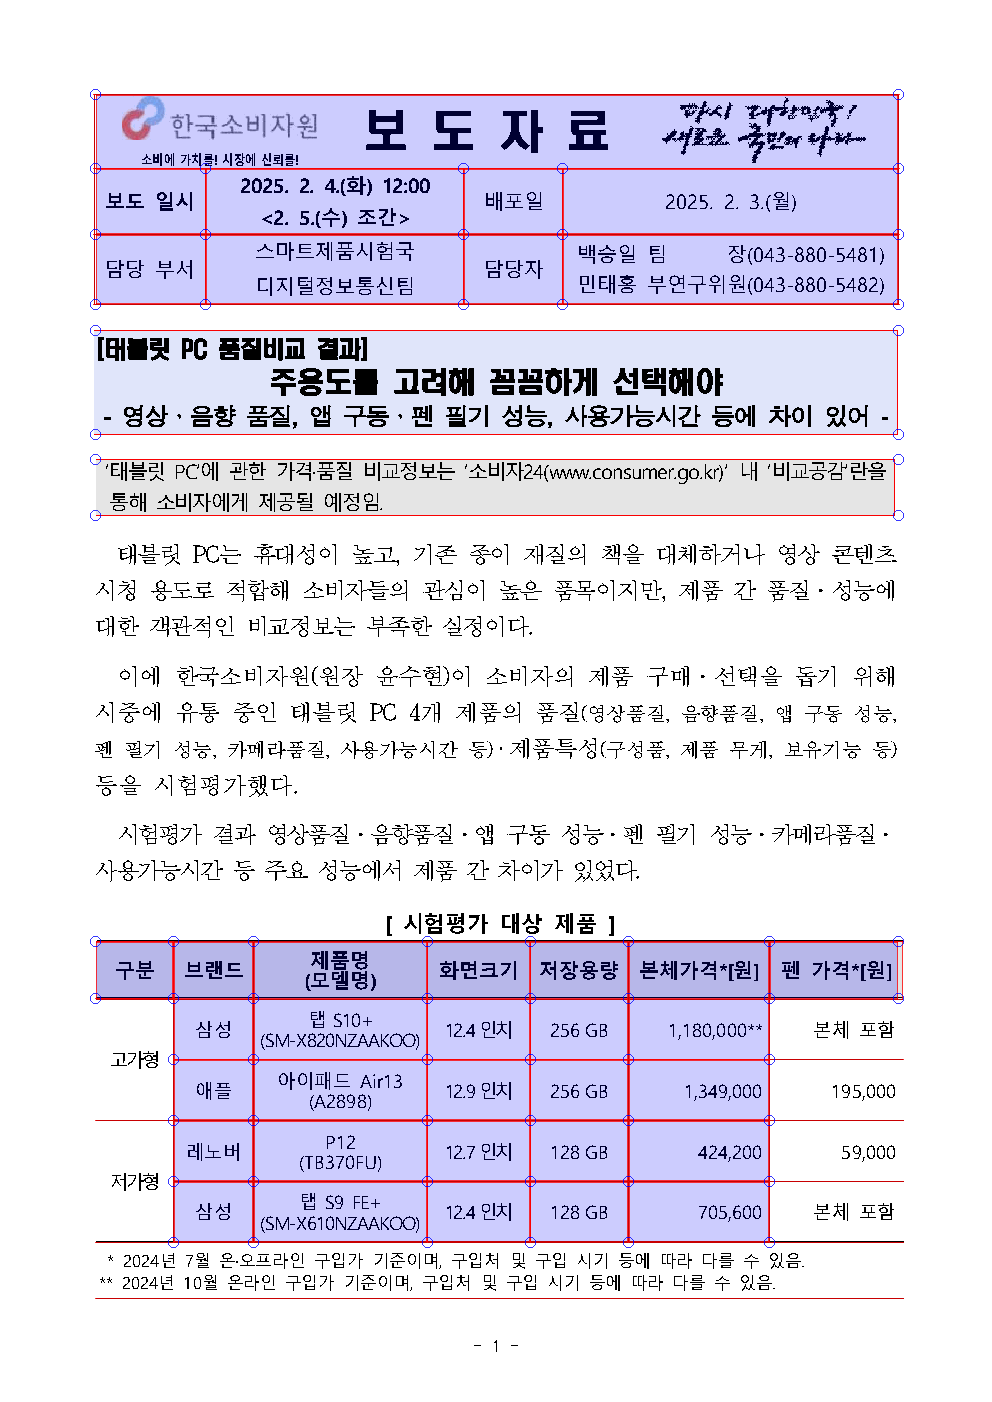

In [5]:
with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[0]
    # 첫 페이지 위에 탐지한 선·교차점·표 영역을 표시해 표 경계를 확인한다.
    display(page.to_image(resolution=120).debug_tablefinder())

### 처리할 표 선택

탐색 결과에서 1페이지의 두 번째 표인 하단 제품표를 선택한다. 목록에 저장한 좌표로 표 영역을 잘라 내용을 확인한다.

1페이지 표 2


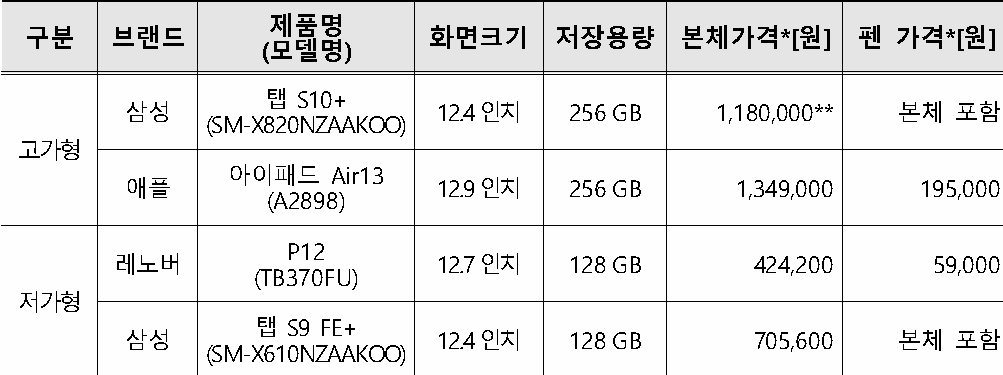

In [6]:
# 표 후보 중 1페이지의 두 번째 표를 선택한다.
TABLE_PAGE_NO = 1
TABLE_NO = 2

# 페이지와 표 번호가 일치하는 첫 후보를 가져오고, 없으면 None을 반환한다.
selected_table = next(
    (table_info for table_info in table_candidates
     if table_info["page_no"] == TABLE_PAGE_NO and table_info["table_no"] == TABLE_NO),
    None,
)
if selected_table is None:
    raise ValueError("선택한 표 후보가 없습니다.")

# 선택한 좌표는 표 추출과 본문 교체에 사용한다.
table_bbox = selected_table["bbox"]
with pdfplumber.open(pdf_path) as pdf:
    # 페이지 번호는 1부터, pdf.pages의 인덱스는 0부터 시작한다.
    page = pdf.pages[TABLE_PAGE_NO - 1]
    print(f"{TABLE_PAGE_NO}페이지 표 {TABLE_NO}")
    # 선택한 영역만 잘라 이미지로 확인한다.
    display(page.crop(table_bbox).to_image(resolution=150))

### 표 내용 추출

예제 표는 양쪽 바깥 세로선이 없어 표 영역의 좌우 좌표로 경계를 보완한다. 표 아래의 각주도 함께 가져온다.

In [7]:
# 선택한 표에서 빠진 경계를 보완해 행과 열을 다시 추출한다.
table_settings = {
    "vertical_strategy": "lines",  # 세로선으로 열 경계를 찾는다.
    "horizontal_strategy": "lines",  # 가로선으로 행 경계를 찾는다.
    "explicit_vertical_lines": [table_bbox[0], table_bbox[2]],  # 빠진 좌우 경계를 보완한다.
}

with pdfplumber.open(pdf_path) as pdf:
    page = pdf.pages[TABLE_PAGE_NO - 1]
    region = page.crop(table_bbox)  # 선택한 표 영역만 잘라낸다.
    corrected_tables = region.find_tables(table_settings)  # 보완한 설정으로 표를 다시 찾는다.
    if not corrected_tables:
        raise ValueError("보완한 설정에서 표를 찾지 못했습니다.")
    corrected_rows = corrected_tables[0].extract()  # 셀 내용을 행별 리스트로 추출한다.

    # 표 아래에서 별표로 시작하는 각주 줄을 찾는다.
    footnote_lines = [
        line for line in page.extract_text_lines(return_chars=False)
        if line["top"] >= table_bbox[3] and line["text"].startswith("*")
    ]
    # 각주 텍스트는 표와 함께 보관하고 이후 표 청크에도 붙인다.
    footnotes = "\n".join(line["text"] for line in footnote_lines)
    # 마지막 각주까지 영역을 확장한다. 각주가 없으면 기존 하단 경계를 유지한다.
    table_with_footnotes_bbox = (
        table_bbox[0], table_bbox[1], table_bbox[2],
        max((line["bottom"] for line in footnote_lines), default=table_bbox[3]),
    )

pprint(corrected_rows)
print("\n각주:", footnotes)

[['구분', '브랜드', '제품명\n(모델명)', '화면크기', '저장용량', '본체가격*[원]', '펜 가격*[원]'],
 ['고가형',
  '삼성',
  '탭 S10+\n(SM-X820NZAAKOO)',
  '12.4인치',
  '256GB',
  '1,180,000**',
  '본체 포함'],
 [None, '애플', '아이패드 Air13\n(A2898)', '12.9인치', '256GB', '1,349,000', '195,000'],
 ['저가형', '레노버', 'P12\n(TB370FU)', '12.7인치', '128GB', '424,200', '59,000'],
 [None,
  '삼성',
  '탭 S9 FE+\n(SM-X610NZAAKOO)',
  '12.4인치',
  '128GB',
  '705,600',
  '본체 포함']]

각주: * 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.
** 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.


### 셀 내용 정리

병합된 셀에서는 일부 행의 구분 값이 비어 있을 수 있다. 각 제품 행을 독립적으로 읽을 수 있도록 같은 범주의 값을 채우고, 셀 안의 불필요한 줄바꿈을 정리한다.

In [8]:
# 빈 셀은 빈 문자열로 바꾸고, 줄바꿈과 연속 공백은 한 칸으로 정리한다.
def normalize_cell(value):
    return " ".join((value or "").split())

# 첫 행은 열 이름으로, 나머지 행은 제품 데이터로 사용한다.
headers = [normalize_cell(value) for value in corrected_rows[0]]
rows = []
current_category = ""
for extracted_row in corrected_rows[1:]:
    row = [normalize_cell(value) for value in extracted_row]
    # 병합된 구분 셀의 빈칸에는 직전에 읽은 구분 값을 채운다.
    if row[0]:
        current_category = row[0]
    else:
        row[0] = current_category
    rows.append(row)

pprint(rows)

[['고가형',
  '삼성',
  '탭 S10+ (SM-X820NZAAKOO)',
  '12.4인치',
  '256GB',
  '1,180,000**',
  '본체 포함'],
 ['고가형', '애플', '아이패드 Air13 (A2898)', '12.9인치', '256GB', '1,349,000', '195,000'],
 ['저가형', '레노버', 'P12 (TB370FU)', '12.7인치', '128GB', '424,200', '59,000'],
 ['저가형',
  '삼성',
  '탭 S9 FE+ (SM-X610NZAAKOO)',
  '12.4인치',
  '128GB',
  '705,600',
  '본체 포함']]


### Markdown 표로 표현

정리한 행과 열을 Markdown 표로 만들고 각주를 붙인다. 원본과 비교하여 값이 맞는지 확인한다.

In [9]:
# 셀 목록을 Markdown 표의 한 행으로 변환한다.
def markdown_row(values):
    # 셀 값 안의 |가 열 구분자로 해석되지 않도록 이스케이프한다.
    escaped = [value.replace("|", r"\|") for value in values]
    return "| " + " | ".join(escaped) + " |"

# 열 이름, 헤더 구분선, 데이터 행 순서로 표를 구성한다.
table_markdown = "\n".join([
    markdown_row(headers),
    markdown_row(["---"] * len(headers)),
    *[markdown_row(row) for row in rows],
])
# 각주의 별표가 Markdown 목록이나 강조 표시로 해석되지 않도록 처리한다.
footnotes_markdown = "\n\n".join(
    line.replace("*", r"\*") for line in footnotes.splitlines()
)
# 본문에 넣을 교체 텍스트에는 표와 각주를 함께 포함한다.
table_content = f"{table_markdown}\n\n{footnotes_markdown}"

# 원본 문자열과 렌더링한 표를 비교해 형식을 확인한다.
print(table_content)
display(Markdown(table_content))

# 표마다 텍스트와 행·열 구조를 함께 보관한다. 여러 표는 이 목록에 추가한다.
table_results = [{
    "page_no": TABLE_PAGE_NO,
    "bbox": table_with_footnotes_bbox,
    "content_type": "table",
    "table_id": f"page-{TABLE_PAGE_NO}-table-{TABLE_NO}",
    "text": table_content,
    "headers": headers,
    "rows": rows,
    "footnotes": footnotes_markdown,
}]

| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 삼성 | 탭 S10+ (SM-X820NZAAKOO) | 12.4인치 | 256GB | 1,180,000** | 본체 포함 |
| 고가형 | 애플 | 아이패드 Air13 (A2898) | 12.9인치 | 256GB | 1,349,000 | 195,000 |
| 저가형 | 레노버 | P12 (TB370FU) | 12.7인치 | 128GB | 424,200 | 59,000 |
| 저가형 | 삼성 | 탭 S9 FE+ (SM-X610NZAAKOO) | 12.4인치 | 128GB | 705,600 | 본체 포함 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 삼성 | 탭 S10+ (SM-X820NZAAKOO) | 12.4인치 | 256GB | 1,180,000** | 본체 포함 |
| 고가형 | 애플 | 아이패드 Air13 (A2898) | 12.9인치 | 256GB | 1,349,000 | 195,000 |
| 저가형 | 레노버 | P12 (TB370FU) | 12.7인치 | 128GB | 424,200 | 59,000 |
| 저가형 | 삼성 | 탭 S9 FE+ (SM-X610NZAAKOO) | 12.4인치 | 128GB | 705,600 | 본체 포함 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

### 이미지의 내용 읽기

PDF에 저장된 이미지에는 로고나 아이콘도 포함된다. 이미지가 페이지에서 차지하는 면적을 기준으로 읽을 대상을 고르고, Gemini로 내용을 추출한다.

**이미지 탐색 → 면적 기준으로 선택 → 이미지 확인 → Gemini로 내용 추출**

In [10]:
# 이미지 후보의 위치와 페이지 대비 면적 비율을 저장한다.
image_candidates = []

with pdfplumber.open(pdf_path) as pdf:
    for page_no, page in enumerate(pdf.pages, start=1):
        page_area = page.width * page.height
        # PDF 내부에 이미지로 저장된 객체를 찾는다. 로고나 아이콘도 포함된다.
        for image_index, img in enumerate(page.images, start=1):
            # 표와 같은 좌표 순서를 사용해 나중에 동일한 교체 함수로 처리한다.
            bbox = (img["x0"], img["top"], img["x1"], img["bottom"])
            image_area = (bbox[2] - bbox[0]) * (bbox[3] - bbox[1])
            image_candidates.append({
                "page_no": page_no,
                "image_index": image_index,
                "bbox": bbox,
                "area_ratio": image_area / page_area,  # 작은 이미지 후보를 걸러내는 기준이다.
            })
        if page.images:
            print(f"{page_no}페이지: 이미지 {len(page.images)}개")

print(f"전체 이미지: {len(image_candidates)}개")

1페이지: 이미지 2개
4페이지: 이미지 2개
5페이지: 이미지 1개
11페이지: 이미지 5개
15페이지: 이미지 4개
전체 이미지: 14개


### 읽을 이미지 선택

이 예제에서는 페이지 면적의 10%를 초과하는 이미지를 선택한다. 선택한 이미지가 읽으려는 내용을 포함하는지 미리보기로 확인한다.

In [11]:
MIN_IMAGE_AREA_RATIO = 0.10  # 페이지 면적의 10%를 초과하는 이미지를 선택한다.
# 면적 기준을 만족한 후보의 좌표와 페이지 정보를 그대로 유지한다.
selected_images = [
    image_info for image_info in image_candidates
    if image_info["area_ratio"] > MIN_IMAGE_AREA_RATIO
]

print(f"전체 {len(image_candidates)}개 중 선택한 이미지: {len(selected_images)}개")
# 모델에 전달할 후보의 페이지와 크기를 확인한다.
for image_info in selected_images:
    print(
        f"{image_info['page_no']}페이지 이미지 {image_info['image_index']} | "
        f"페이지 면적의 {image_info['area_ratio']:.1%}"
    )

전체 14개 중 선택한 이미지: 1개
5페이지 이미지 1 | 페이지 면적의 65.0%


### 선택한 이미지 확인

선택한 영역을 이미지로 확인한다. 읽어야 할 글자나 그림이 잘리지 않았는지 확인한 뒤 Gemini에 전달한다.

5페이지 이미지 1


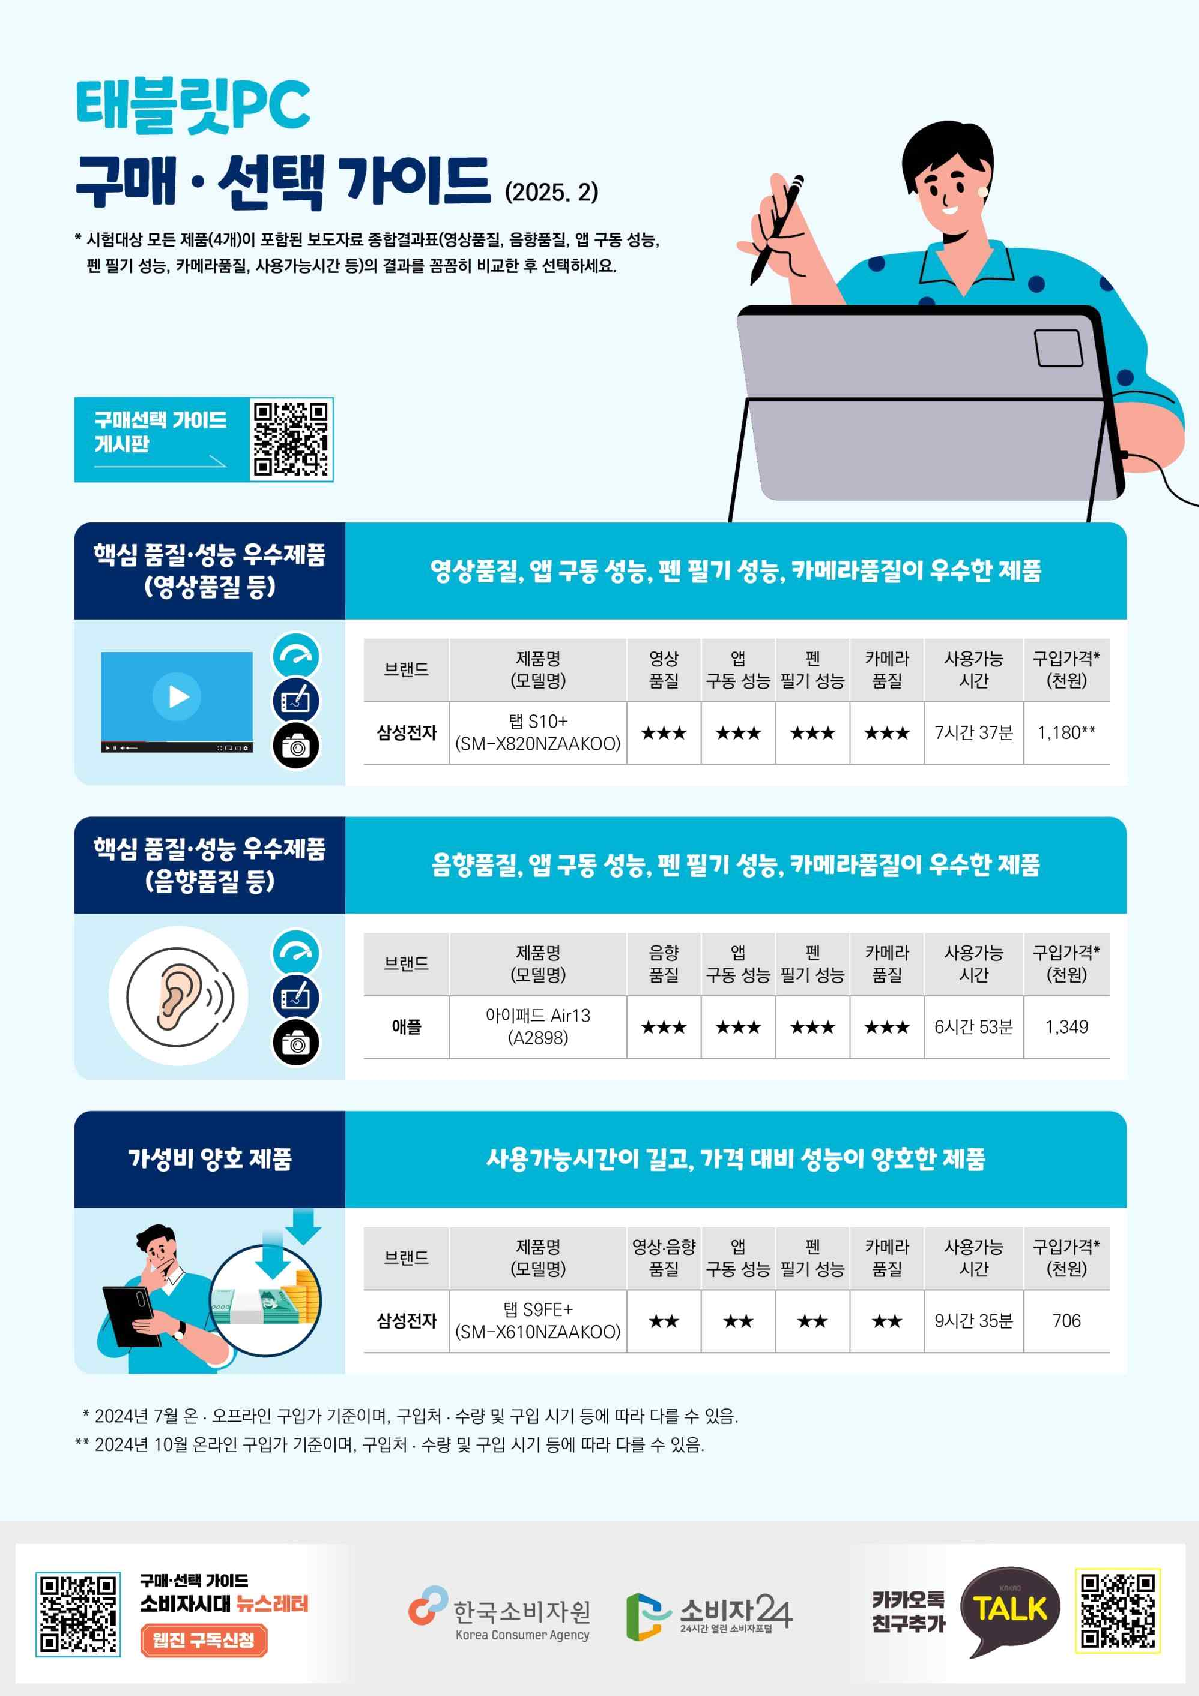

In [12]:
with pdfplumber.open(pdf_path) as pdf:
    for image_info in selected_images:
        page = pdf.pages[image_info["page_no"] - 1]
        # 선택한 이미지 영역을 잘라 PNG로 저장할 수 있는 이미지로 렌더링한다.
        image_preview = page.crop(image_info["bbox"]).to_image(resolution=180)
        # 메모리 버퍼에 PNG를 저장해 별도 이미지 파일 없이 전달한다.
        buffer = BytesIO()
        image_preview.original.save(buffer, format="PNG")
        # PNG 바이트를 후보 정보에 추가해 다음 모델 호출에서 사용한다.
        image_info["image_bytes"] = buffer.getvalue()

        print(f"{image_info['page_no']}페이지 이미지 {image_info['image_index']}")
        display(Image(data=image_info["image_bytes"], width=700))

### Gemini 준비

선택한 이미지의 내용을 Gemini로 읽어 Markdown으로 변환한다.

In [13]:
load_dotenv(".env", override=True)
MODEL_NAME = "gemini-3.6-flash"
llm = ChatGoogleGenerativeAI(model=MODEL_NAME, timeout=90, max_retries=1)
parser = StrOutputParser()

Both GOOGLE_API_KEY and GEMINI_API_KEY are set. Using GOOGLE_API_KEY.


### 추출 지시문

검색에 필요한 내용이 빠지지 않도록 요약 대신 이미지 속 본문과 표를 보존하도록 요청한다.

In [14]:
# 이미지의 표·수치·각주를 보존하고 읽을 수 없는 내용은 구분하도록 지시한다.
extraction_prompt = """첨부한 이미지의 내용을 RAG용 Markdown으로 변환하세요.
- 제목과 본문을 읽기 순서대로 작성하고, 내용을 요약하거나 생략하지 마세요.
- 표는 열 이름과 값의 관계가 드러나는 Markdown 표로 작성하세요.
- 수치, 단위, 제품명과 각주를 보존하고, 각주 번호는 수치와 구분하세요.
- 그림 설명은 [그림 설명]으로 구분하세요.
- 읽을 수 없는 부분은 [확인 불가]로 표시하고 내용을 추측하지 마세요.
- 결과 전체를 코드 블록으로 감싸지 마세요.
"""

### Gemini로 이미지 내용 추출

선택한 이미지를 하나씩 Gemini에 전달하고 결과를 Markdown으로 표시한다. 각 이미지와 비교하여 내용과 숫자가 맞는지 확인한다.

In [15]:
# 이미지 해석 결과를 원래 페이지와 영역 좌표에 연결해 저장한다.
image_results = []

for image_info in selected_images:
    # 선택한 이미지마다 텍스트 지시와 이미지 데이터를 하나의 메시지에 담는다.
    message = HumanMessage(content=[
        {"type": "text", "text": extraction_prompt},
        {
            "type": "image",
            # PNG 바이트를 Base64로 인코딩하고 JSON에 넣을 문자열로 변환한다.
            "base64": base64.b64encode(image_info["image_bytes"]).decode("ascii"),
            "mime_type": "image/png",
        },
    ])
    # 모델을 호출하고 응답 텍스트 양끝의 공백을 제거한다.
    response = llm.invoke([message])
    image_text = parser.invoke(response).strip()
    # 빈 응답으로 기존 영역의 내용을 교체하지 않도록 중단한다.
    if not image_text:
        raise ValueError(
            f"{image_info['page_no']}페이지 이미지 {image_info['image_index']}: 추출 결과가 비어 있습니다."
        )

    # bbox를 보관해야 해석한 내용을 원래 페이지의 해당 위치에 넣을 수 있다.
    image_results.append({
        "page_no": image_info["page_no"],
        "image_index": image_info["image_index"],
        "bbox": image_info["bbox"],
        "content_type": "image",
        "image_id": f"page-{image_info['page_no']}-image-{image_info['image_index']}",
        "text": image_text,
    })
    print(f"{image_info['page_no']}페이지 이미지 {image_info['image_index']}")
    # 원본 이미지와 대조할 수 있도록 해석 결과를 렌더링한다.
    display(Markdown(image_text))

Direct use of automatic function calling (AFC) in Models.generate_content is not recommended. Instead, we recommend to use AFC in Chat.send_message. Similarly, direct use of AFC in Models.generate_content_stream is not recommended. Instead, we recommend to use AFC in Chat.send_message_stream.


5페이지 이미지 1


# 태블릿PC 구매·선택 가이드 (2025. 2)

* 시험대상 모든 제품(4개)이 포함된 보도자료 종합결과표(영상품질, 음향품질, 앱 구동 성능, 펜 필기 성능, 카메라품질, 사용가능시간 등)의 결과를 꼼꼼히 비교한 후 선택하세요.

구매선택 가이드 게시판 [QR코드]

[그림 설명: 사람이 태블릿PC와 펜슬을 사용하고 있는 일러스트]

---

## 핵심 품질·성능 우수제품 (영상품질 등)
### 영상품질, 앱 구동 성능, 펜 필기 성능, 카메라품질이 우수한 제품

[그림 설명: 비디오 재생 화면과 재생, 펜, 카메라 기능 아이콘]

| 브랜드 | 제품명 (모델명) | 영상품질 | 앱 구동 성능 | 펜 필기 성능 | 카메라 품질 | 사용가능 시간 | 구입가격* (천원) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 삼성전자 | 탭 S10+ (SM-X820NZAAKOO) | ★★★ | ★★★ | ★★★ | ★★★ | 7시간 37분 | 1,180** |

---

## 핵심 품질·성능 우수제품 (음향품질 등)
### 음향품질, 앱 구동 성능, 펜 필기 성능, 카메라품질이 우수한 제품

[그림 설명: 귀 모양 아이콘과 음향, 펜, 카메라 기능 아이콘]

| 브랜드 | 제품명 (모델명) | 음향품질 | 앱 구동 성능 | 펜 필기 성능 | 카메라 품질 | 사용가능 시간 | 구입가격* (천원) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 애플 | 아이패드 Air13 (A2898) | ★★★ | ★★★ | ★★★ | ★★★ | 6시간 53분 | 1,349 |

---

## 가성비 양호 제품
### 사용가능시간이 길고, 가격 대비 성능이 양호한 제품

[그림 설명: 태블릿PC와 돈(지폐, 동전)을 바라보고 있는 일러스트]

| 브랜드 | 제품명 (모델명) | 영상·음향 품질 | 앱 구동 성능 | 펜 필기 성능 | 카메라 품질 | 사용가능 시간 | 구입가격* (천원) |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 삼성전자 | 탭 S9FE+ (SM-X610NZAAKOO) | ★★ | ★★ | ★★ | ★★ | 9시간 35분 | 706 |

---

* 2024년 7월 온·오프라인 구입가 기준이며, 구입처·수량 및 구입 시기 등에 따라 다를 수 있음.
** 2024년 10월 온라인 구입가 기준이며, 구입처·수량 및 구입 시기 등에 따라 다를 수 있음.

---

[QR코드] 구매·선택 가이드 소비자시대 뉴스레터 웹진 구독신청
한국소비자원 Korea Consumer Agency
소비자24 24시간 열린 소비자포털
카카오톡 친구추가 [QR코드]

### 청킹을 위해 본문·표·이미지 내용을 구분하기

PDF에서 추출한 내용을 한꺼번에 길이 기준으로 청킹하면 표 중간이 잘릴 수 있다. 그러면 열 이름과 데이터 행, 각주가 서로 다른 청크로 나뉘어 검색된 내용만으로 표를 이해하기 어려워진다.

이를 방지하기 위해 청킹 전에 본문 텍스트, 표, 이미지에서 읽은 내용을 구분해 보관한다. 본문과 이미지 해석 텍스트에는 일반 청킹을 적용하고, 표는 크기에 따라 통째로 유지하거나 헤더·각주를 붙여 행 단위로 나눈다.

### 본문과 추출 결과의 순서 유지

표·이미지 영역에서 읽힌 기존 글자는 제외하고, 그 위치에 정리한 표와 이미지 해석 결과를 배치한다. 같은 내용이 중복되지 않도록 하면서 주변 본문과 원래 위치 관계를 유지한다.

```text
PDF 페이지 → [본문 텍스트] [표] [본문 텍스트] [이미지 해석 결과]
```

표나 이미지가 여러 개 있어도 각각 구분하고, 사이에 있는 본문은 이어서 읽을 수 있도록 묶는다.

In [16]:
# 선택한 영역의 텍스트와 구조를 보존한 채 페이지를 블록 목록으로 만든다.
# 원본 PDF는 변경하지 않고, 유형·내용·좌표가 있는 딕셔너리 목록을 반환한다.
def build_page_blocks(page, regions):
    def outside_regions(obj):
        # 글자의 중심점이 표·이미지 영역 안에 있으면 기존 글자를 제외한다.
        if obj["object_type"] != "char":
            return True
        center_x = (obj["x0"] + obj["x1"]) / 2
        center_y = (obj["top"] + obj["bottom"]) / 2
        return not any(
            region["bbox"][0] <= center_x <= region["bbox"][2]
            and region["bbox"][1] <= center_y <= region["bbox"][3]
            for region in regions
        )

    # 남은 본문 줄을 텍스트와 영역 좌표가 있는 블록으로 만든다.
    body_page = page.filter(outside_regions)
    positioned_blocks = [
        {
            "content_type": "text",
            "text": line["text"],
            "bbox": (line["x0"], line["top"], line["x1"], line["bottom"]),
        }
        for line in body_page.extract_text_lines(return_chars=False)
    ]
    # 표의 헤더·행·각주와 이미지 ID를 포함해 추출 결과를 복사한다.
    positioned_blocks.extend(dict(region) for region in regions)
    # bbox의 위쪽 좌표를 먼저, 높이가 같으면 왼쪽 좌표를 기준으로 정렬한다.
    positioned_blocks.sort(key=lambda block: (block["bbox"][1], block["bbox"][0]))

    blocks = []
    for block in positioned_blocks:
        # 표나 이미지 사이에 연속해서 나온 본문 줄만 하나로 합친다.
        if blocks and block["content_type"] == "text" and blocks[-1]["content_type"] == "text":
            previous = blocks[-1]
            previous["text"] += "\n" + block["text"]
            x0, top, x1, bottom = previous["bbox"]
            bx0, btop, bx1, bbottom = block["bbox"]
            previous["bbox"] = (min(x0, bx0), min(top, btop), max(x1, bx1), max(bottom, bbottom))
        else:
            blocks.append(block)
    return blocks

In [17]:
# 추출한 표와 이미지를 페이지별로 모은다. 각 결과의 구조와 ID를 유지한다.
regions_by_page = {}
for result in table_results + image_results:
    regions_by_page.setdefault(result["page_no"], []).append(result)

document_blocks = []
rag_documents = []
with pdfplumber.open(pdf_path) as pdf:
    for doc in docs:
        # 로더의 페이지 인덱스를 1부터 시작하는 페이지 번호로 맞춘다.
        page_no = doc.metadata["page"] + 1
        page = pdf.pages[page_no - 1]
        regions = regions_by_page.get(page_no, [])
        if regions:
            page_blocks = build_page_blocks(page, regions)
            has_image = any(region["content_type"] == "image" for region in regions)
            extraction_method = "pdfplumber+gemini" if has_image else "pdfplumber"
        else:
            # 선택한 표·이미지가 없는 페이지는 기존 본문을 텍스트 블록으로 보관한다.
            page_blocks = [{"content_type": "text", "text": doc.page_content, "bbox": page.bbox}]
            extraction_method = "pypdf"

        page_metadata = {
            **doc.metadata,
            "file_name": pdf_path.name,
            "page_no": page_no,
            "extraction_method": extraction_method,
        }
        for block_index, block in enumerate(page_blocks):
            # 출처와 유형, 블록 ID는 이후 생성되는 모든 청크에 전달한다.
            block["metadata"] = {
                **page_metadata,
                "content_type": block["content_type"],
                "block_id": f"page-{page_no}-block-{block_index}",
            }
            for key in ("table_id", "image_id"):
                if key in block:
                    block["metadata"][key] = block[key]
        document_blocks.extend(page_blocks)

        # 일반 청킹과 비교할 페이지 본문도 만든다. 원래 블록은 별도로 유지한다.
        rag_documents.append(Document(
            page_content="\n\n".join(block["text"] for block in page_blocks).strip(),
            metadata=page_metadata,
        ))

for block in document_blocks:
    print(
        f"{block['metadata']['page_no']:>2}페이지 | "
        f"{block['content_type']:<5} | {len(block['text']):>5}자"
    )

 1페이지 | text  |   670자
 1페이지 | table |   511자
 1페이지 | text  |     5자
 2페이지 | text  |  1020자
 3페이지 | text  |  1111자
 4페이지 | text  |    85자
 5페이지 | image |  1351자
 5페이지 | text  |     5자
 6페이지 | text  |   928자
 7페이지 | text  |  1479자
 8페이지 | text  |  1158자
 9페이지 | text  |   864자
10페이지 | text  |   911자
11페이지 | text  |   899자
12페이지 | text  |  1087자
13페이지 | text  |  1221자
14페이지 | text  |   860자
15페이지 | text  |   192자


### PDF 본문 청킹

먼저 유형 구분 없이 페이지 본문에 일반 청킹을 적용한다. 최대 1,000자, 겹침 목표 100자로 나누어 결과를 살펴본다.

실제 겹침은 문단·줄바꿈에 따라 달라지고, 긴 표는 청크 경계에서 나뉠 수 있다. 이후 본문과 표를 구분해 청킹한 결과와 비교한다.

In [18]:
# 문단·줄바꿈 등의 경계를 이용해 본문을 길이 기준으로 나눈다.
splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,  # 기본 길이 계산인 문자 수를 기준으로 한다.
    chunk_overlap=100,  # 겹침 목표이며, 실제 겹침은 분할 경계에 따라 달라진다.
)
# 페이지별로 나누며 원래 Document의 출처 메타데이터를 각 청크에 복사한다.
chunks = splitter.split_documents(rag_documents)

# 전체 PDF에서 청크를 구분할 수 있도록 0부터 순번을 붙인다.
for index, chunk in enumerate(chunks):
    chunk.metadata["chunk_index"] = index

print(f"PDF 페이지 수: {len(rag_documents)}")
print(f"생성한 청크 수: {len(chunks)}")
# 청크가 만들어진 페이지와 문자 수를 확인한다.
for chunk in chunks:
    print(
        f"청크 {chunk.metadata['chunk_index']:>2} | "
        f"{chunk.metadata['page_no']:>2}페이지 | {len(chunk.page_content):>4}자"
    )

PDF 페이지 수: 15
생성한 청크 수: 23
청크  0 |  1페이지 |  670자
청크  1 |  1페이지 |  518자
청크  2 |  2페이지 |  966자
청크  3 |  2페이지 |  124자
청크  4 |  3페이지 |  989자
청크  5 |  3페이지 |  211자
청크  6 |  4페이지 |   85자
청크  7 |  5페이지 |  916자
청크  8 |  5페이지 |  533자
청크  9 |  6페이지 |  928자
청크 10 |  7페이지 |  992자
청크 11 |  7페이지 |  558자
청크 12 |  8페이지 |  997자
청크 13 |  8페이지 |  240자
청크 14 |  9페이지 |  864자
청크 15 | 10페이지 |  911자
청크 16 | 11페이지 |  899자
청크 17 | 12페이지 |  976자
청크 18 | 12페이지 |  210자
청크 19 | 13페이지 |  998자
청크 20 | 13페이지 |  311자
청크 21 | 14페이지 |  860자
청크 22 | 15페이지 |  192자


### 청킹 결과 확인

1페이지에서 표와 각주가 같은 청크에 포함되는지, 원문 출처를 확인할 수 있는지 살펴본다.

이 예제에서는 표와 각주 511자가 1,000자 기준의 청크 하나에 함께 들어간다. 이는 현재 텍스트의 길이와 줄바꿈에 따른 결과다. 일반 청킹은 표 구조를 따로 판단하지 않으므로 기준 길이를 줄이거나 표가 길어지면 표가 나뉠 수 있다.

In [19]:
for chunk in chunks:
    # 제품표가 있는 페이지만 골라 표와 각주가 같은 청크에 남았는지 확인한다.
    if chunk.metadata["page_no"] == TABLE_PAGE_NO:
        print(chunk.metadata)
        display(Markdown(chunk.page_content))

{'producer': 'Hancom PDF 1.3.0.542', 'creator': 'Hwp 2020 11.0.0.4278', 'creationdate': '2025-01-31T09:35:50+09:00', 'author': '2012138', 'moddate': '2025-01-31T09:35:50+09:00', 'pdfversion': '1.4', 'source': 'data\\250204_태블릿+PC+품질비교시험_보도자료.pdf', 'total_pages': 15, 'page': 0, 'page_label': '1', 'file_name': '250204_태블릿+PC+품질비교시험_보도자료.pdf', 'page_no': 1, 'extraction_method': 'pdfplumber', 'chunk_index': 0}


보 도 자 료
소비에 가치를! 시장에 신뢰를!
2025. 2. 4.(화) 12:00
보도 일시 배포일 2025. 2. 3.(월)
<2. 5.(수) 조간>
스마트제품시험국 백승일 팀 장(043-880-5481)
담당 부서 담당자
디지털정보통신팀 민태홍 부연구위원(043-880-5482)
[태블릿 PC 품질비교 결과]
주용도를 고려해 꼼꼼하게 선택해야
- 영상ㆍ음향 품질, 앱 구동ㆍ펜 필기 성능, 사용가능시간 등에 차이 있어 -
‘태블릿 PC’에 관한 가격·품질 비교정보는 ‘소비자24(www.consumer.go.kr)’ 내 ‘비교공감’란을
통해 소비자에게 제공될 예정임.
태블릿 PC는 휴대성이 높고, 기존 종이 재질의 책을 대체하거나 영상 콘텐츠
시청 용도로 적합해 소비자들의 관심이 높은 품목이지만, 제품 간 품질·성능에
대한 객관적인 비교정보는 부족한 실정이다.
이에 한국소비자원(원장 윤수현)이 소비자의 제품 구매·선택을 돕기 위해
시중에 유통 중인 태블릿 PC 4개 제품의 품질(영상품질, 음향품질, 앱 구동 성능,
펜 필기 성능, 카메라품질, 사용가능시간 등) ‧ 제품특성(구성품, 제품 무게, 보유기능 등)
등을 시험평가했다.
시험평가 결과 영상품질·음향품질·앱 구동 성능·펜 필기 성능·카메라품질·
사용가능시간 등 주요 성능에서 제품 간 차이가 있었다.
[ 시험평가 대상 제품 ]

{'producer': 'Hancom PDF 1.3.0.542', 'creator': 'Hwp 2020 11.0.0.4278', 'creationdate': '2025-01-31T09:35:50+09:00', 'author': '2012138', 'moddate': '2025-01-31T09:35:50+09:00', 'pdfversion': '1.4', 'source': 'data\\250204_태블릿+PC+품질비교시험_보도자료.pdf', 'total_pages': 15, 'page': 0, 'page_label': '1', 'file_name': '250204_태블릿+PC+품질비교시험_보도자료.pdf', 'page_no': 1, 'extraction_method': 'pdfplumber', 'chunk_index': 1}


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 삼성 | 탭 S10+ (SM-X820NZAAKOO) | 12.4인치 | 256GB | 1,180,000** | 본체 포함 |
| 고가형 | 애플 | 아이패드 Air13 (A2898) | 12.9인치 | 256GB | 1,349,000 | 195,000 |
| 저가형 | 레노버 | P12 (TB370FU) | 12.7인치 | 128GB | 424,200 | 59,000 |
| 저가형 | 삼성 | 탭 S9 FE+ (SM-X610NZAAKOO) | 12.4인치 | 128GB | 705,600 | 본체 포함 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

- 1 -

### 길이 기준 청킹에서 표가 나뉘는 경우

이번에는 같은 제품표와 각주를 300자 기준으로 나누어 본다. 1,000자 기준에서 함께 유지되던 내용이 여러 청크로 나뉘고, 열 이름은 첫 번째 청크에만 남는다. 뒤쪽 청크에는 데이터 행이나 각주만 남을 수 있다.

청크 하나만 검색되었을 때 제품명·가격·단위의 관계를 읽을 수 있는지 확인한다.

In [20]:
# 표가 나뉘는 현상을 확인하기 위해 비교용 길이를 작게 설정한다.
# 1,000으로 바꾸고 아래 청킹 셀들을 다시 실행하면 길이에 따른 차이를 비교할 수 있다.
TABLE_DEMO_CHUNK_SIZE = 300
comparison_splitter = RecursiveCharacterTextSplitter(
    chunk_size=TABLE_DEMO_CHUNK_SIZE,
    chunk_overlap=0,  # 겹침 없이 나누어 각 청크에 남는 내용을 비교한다.
)

# 표 구조를 별도로 처리하지 않고 Markdown 문자열에 일반 청킹을 적용한다.
naive_table_chunks = comparison_splitter.split_text(table_content)
# 열 이름·데이터 행·각주가 서로 다른 청크로 나뉘는지 확인한다.
for index, text in enumerate(naive_table_chunks, start=1):
    print(f"일반 청킹 {index} | {len(text)}자")
    display(Markdown(text))

일반 청킹 1 | 255자


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 삼성 | 탭 S10+ (SM-X820NZAAKOO) | 12.4인치 | 256GB | 1,180,000** | 본체 포함 |
| 고가형 | 애플 | 아이패드 Air13 (A2898) | 12.9인치 | 256GB | 1,349,000 | 195,000 |

일반 청킹 2 | 141자


| 저가형 | 레노버 | P12 (TB370FU) | 12.7인치 | 128GB | 424,200 | 59,000 |
| 저가형 | 삼성 | 탭 S9 FE+ (SM-X610NZAAKOO) | 12.4인치 | 128GB | 705,600 | 본체 포함 |

일반 청킹 3 | 112자


\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

### 구분한 본문과 표 확인

제품표가 있는 페이지에서 표 앞뒤의 본문과 표가 각각 구분되어 있는지 확인한다. 이때 표와 각주는 함께 유지되어야 한다.

In [21]:
# 페이지 번호로 이미 구성된 블록을 선택한다. 표 문자열을 다시 검색하지 않는다.
page_blocks = [
    block for block in document_blocks
    if block["metadata"]["page_no"] == TABLE_PAGE_NO
]
for block in page_blocks:
    print(f"{block['content_type']:<5} | {len(block['text'])}자")
    if block["content_type"] == "table":
        print(f"  {block['table_id']} | {len(block['headers'])}개 열 | {len(block['rows'])}개 데이터 행")

text  | 670자
table | 511자
  page-1-table-2 | 7개 열 | 4개 데이터 행
text  | 5자


### 표를 통째로 유지하기

본문과 이미지 해석 텍스트만 길이 기준으로 나누고, 표와 각주는 하나의 청크로 유지한다.

이 방법은 표가 중간에 잘리는 것을 막지만, 청크 길이가 커질 수 있다. 이 예제의 표와 각주는 511자로, 비교 기준인 300자를 초과한다. 표의 내용을 보존하면서 청크 길이도 줄이려면 행 구조를 이용해 나누어야 한다.

In [22]:
# 표는 통째로 유지하고, 나머지 블록에만 일반 청킹을 적용한다.
protected_chunks = []
for block in page_blocks:
    # 청크에는 텍스트와 출처를 담고, 행·열 구조는 원래 블록에 보관한다.
    block_doc = Document(page_content=block["text"], metadata=block["metadata"])
    if block["content_type"] == "table":
        protected_chunks.append(block_doc)
    else:
        protected_chunks.extend(comparison_splitter.split_documents([block_doc]))

# 기준 초과 여부는 표시만 하고 여기서 다시 나누지 않는다.
for chunk in protected_chunks:
    length = len(chunk.page_content)
    status = "기준 초과" if length > TABLE_DEMO_CHUNK_SIZE else "기준 이내"
    print(f"{chunk.metadata['content_type']:<5} | {length:>3}자 | {status}")

text  | 239자 | 기준 이내
text  | 279자 | 기준 이내
text  | 150자 | 기준 이내
table | 511자 | 기준 초과
text  |   5자 | 기준 이내


### 헤더와 각주를 반복하며 행 단위로 나누기

표가 기준 길이 안에 들어오면 통째로 유지하고, 기준을 넘으면 데이터 행 사이에서만 나눈다. 각 청크에 동일한 열 이름과 각주를 붙여 행의 의미를 유지한다. 반복되는 헤더·각주와 줄바꿈도 길이 계산에 포함한다.

제품명과 가격이 분리되지 않도록 한 행은 자르지 않는다. 헤더·각주·한 행만으로 기준 길이를 넘는 경우에는 해당 청크의 길이 초과를 허용한다.

In [23]:
# 한 행을 자르지 않고, 헤더와 각주가 포함된 Markdown 표 문자열 목록을 만든다.
def split_table_rows(headers, rows, footnotes="", chunk_size=1000):
    # 분할 기준은 양수여야 한다.
    if chunk_size <= 0:
        raise ValueError("chunk_size는 양수여야 합니다.")

    # 모든 표 청크에 반복해서 넣을 열 이름과 Markdown 구분선을 준비한다.
    header_lines = [
        markdown_row(headers),
        markdown_row(["---"] * len(headers)),
    ]
    # 각주가 있을 때만 앞에 빈 줄을 붙인다.
    footnote_suffix = f"\n\n{footnotes.strip()}" if footnotes.strip() else ""

    # 길이를 계산할 때도 최종 출력과 같은 헤더·행·각주 문자열을 사용한다.
    def render_table(row_group):
        lines = header_lines + [markdown_row(row) for row in row_group]
        return "\n".join(lines) + footnote_suffix

    parts = []  # 완성된 표 청크를 저장한다.
    current_rows = []  # 현재 청크에 넣을 데이터 행을 모은다.
    for row in rows:
        # 다음 행까지 넣었을 때의 길이를 헤더·각주·줄바꿈을 포함해 확인한다.
        candidate = render_table(current_rows + [row])
        # 다음 행을 넣으면 기준 길이를 넘는 경우, 지금까지 모은 행을 저장한다.
        if current_rows and len(candidate) > chunk_size:
            parts.append(render_table(current_rows))
            current_rows = []
        # 현재 청크가 비어 있으면 한 행은 반드시 넣는다. 한 행만으로 길이가 초과돼도 자르지 않는다.
        current_rows.append(row)

    # 마지막에 남은 행을 저장한다. 데이터 행이 없어도 헤더와 각주를 한 번 반환한다.
    if current_rows or not parts:
        parts.append(render_table(current_rows))
    return parts

### 내용 유형에 맞게 청킹하기

본문과 이미지 해석 텍스트에는 일반 청킹을, 표에는 행 단위 분할을 적용한다. 제품표가 있는 페이지를 300자 기준으로 나누어 각 표 청크에 열 이름과 각주가 함께 남는지 확인한다.

In [24]:
# 각 블록에 보관한 유형과 데이터를 사용하므로 여러 표에도 같은 함수를 적용할 수 있다.
def split_document_blocks(blocks, chunk_size=1000, chunk_overlap=0):
    text_splitter = RecursiveCharacterTextSplitter(
        chunk_size=chunk_size,
        chunk_overlap=chunk_overlap,
    )
    chunks = []
    for block in blocks:
        # 본문과 이미지 해석 결과는 각각의 출처를 유지하며 일반 청킹한다.
        if block["content_type"] != "table":
            block_doc = Document(page_content=block["text"], metadata=block["metadata"])
            chunks.extend(text_splitter.split_documents([block_doc]))
            continue

        # 표마다 자신의 헤더·행·각주를 사용해 행 사이에서만 나눈다.
        table_parts = split_table_rows(
            block["headers"], block["rows"],
            footnotes=block["footnotes"],
            chunk_size=chunk_size,
        )
        # 원래 table_id는 유지하고, 같은 표 안의 청크 순서를 table_part로 기록한다.
        for part_no, text in enumerate(table_parts, start=1):
            chunks.append(Document(
                page_content=text,
                metadata={**block["metadata"], "table_part": part_no},
            ))
    return chunks

table_page_chunks = split_document_blocks(page_blocks, chunk_size=TABLE_DEMO_CHUNK_SIZE)
for chunk in table_page_chunks:
    if chunk.metadata["content_type"] == "table":
        print(
            f"{chunk.metadata['table_id']} | 부분 {chunk.metadata['table_part']} | "
            f"{len(chunk.page_content)}자"
        )
        display(Markdown(chunk.page_content))

page-1-table-2 | 부분 1 | 296자


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 삼성 | 탭 S10+ (SM-X820NZAAKOO) | 12.4인치 | 256GB | 1,180,000** | 본체 포함 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

page-1-table-2 | 부분 2 | 291자


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 고가형 | 애플 | 아이패드 Air13 (A2898) | 12.9인치 | 256GB | 1,349,000 | 195,000 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

page-1-table-2 | 부분 3 | 284자


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 저가형 | 레노버 | P12 (TB370FU) | 12.7인치 | 128GB | 424,200 | 59,000 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

page-1-table-2 | 부분 4 | 294자


| 구분 | 브랜드 | 제품명 (모델명) | 화면크기 | 저장용량 | 본체가격*[원] | 펜 가격*[원] |
| --- | --- | --- | --- | --- | --- | --- |
| 저가형 | 삼성 | 탭 S9 FE+ (SM-X610NZAAKOO) | 12.4인치 | 128GB | 705,600 | 본체 포함 |

\* 2024년 7월 온·오프라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

\*\* 2024년 10월 온라인 구입가 기준이며, 구입처 및 구입 시기 등에 따라 다를 수 있음.

### PDF 전체에 청킹 적용

PDF 전체에 유형별 청킹을 적용하고, 나뉜 내용과 원문 출처를 확인한다.

이 예제에서 행·열 구조를 추출한 표는 1페이지 제품표다. 다른 표에도 같은 방법을 적용하려면 먼저 행·열 구조를 추출해야 한다. 선택하지 않은 표와 이미지 해석 결과 안의 Markdown 표는 일반 청킹 대상이다.

300자는 분할 결과를 살펴보기 위한 값이다. 기준을 1,000자로 늘려 짧은 제품표가 하나의 청크로 유지되는지도 비교한다.

In [25]:
# chunks는 일반 청킹 비교 결과이고, table_aware_chunks는 유형별 청킹 결과다.
# 페이지별 예외 처리 없이 전체 블록에 같은 청킹 함수를 적용한다.
table_aware_chunks = split_document_blocks(document_blocks, chunk_size=TABLE_DEMO_CHUNK_SIZE)

# 출처·블록 ID를 유지하고 전체 문서 순서에 맞춰 청크 번호를 추가한다.
for index, chunk in enumerate(table_aware_chunks):
    chunk.metadata["chunk_index"] = index

print(f"전체 청크 수: {len(table_aware_chunks)}")
for chunk in table_aware_chunks:
    print(
        f"청크 {chunk.metadata['chunk_index']:>2} | "
        f"{chunk.metadata['page_no']:>2}페이지 | "
        f"{chunk.metadata['content_type']:<5} | {len(chunk.page_content):>3}자"
    )

전체 청크 수: 64
청크  0 |  1페이지 | text  | 239자
청크  1 |  1페이지 | text  | 279자
청크  2 |  1페이지 | text  | 150자
청크  3 |  1페이지 | table | 296자
청크  4 |  1페이지 | table | 291자
청크  5 |  1페이지 | table | 284자
청크  6 |  1페이지 | table | 294자
청크  7 |  1페이지 | text  |   5자
청크  8 |  2페이지 | text  | 275자
청크  9 |  2페이지 | text  | 254자
청크 10 |  2페이지 | text  | 274자
청크 11 |  2페이지 | text  | 212자
청크 12 |  3페이지 | text  | 262자
청크 13 |  3페이지 | text  | 263자
청크 14 |  3페이지 | text  | 295자
청크 15 |  3페이지 | text  | 285자
청크 16 |  4페이지 | text  |  85자
청크 17 |  5페이지 | image | 263자
청크 18 |  5페이지 | image | 251자
청크 19 |  5페이지 | image | 105자
청크 20 |  5페이지 | image | 291자
청크 21 |  5페이지 | image | 209자
청크 22 |  5페이지 | image | 222자
청크 23 |  5페이지 | text  |   5자
청크 24 |  6페이지 | text  | 294자
청크 25 |  6페이지 | text  | 276자
청크 26 |  6페이지 | text  | 289자
청크 27 |  6페이지 | text  |  66자
청크 28 |  7페이지 | text  | 267자
청크 29 |  7페이지 | text  | 296자
청크 30 |  7페이지 | text  | 289자
청크 31 |  7페이지 | text  | 271자
청크 32 |  7페이지 | text  | 270자
청크 33 |  7페이지 | text  |  79자
청크

### 임베딩과 검색으로 연결

```text
PDF 텍스트 추출
  → 표·이미지 내용 정리
  → 본문·표·이미지 내용을 구분
  → 유형에 맞게 청킹
  → 임베딩 → 벡터 저장소 → 검색
```

생성한 청크를 임베딩해 벡터 저장소에 넣으면 질문과 관련된 내용을 검색할 수 있다. 각 청크의 출처 정보를 유지하면 검색 결과가 원문 어느 페이지에서 나온 것인지 확인할 수 있다.

### 추가 방법론

- **Contextual Retrieval**: LLM이 문서 전체와 해당 청크를 참고해 생성한 짧은 문맥 설명을 청크 앞에 붙여 임베딩과 검색에 활용한다.
- **표 요약 기반 검색**: 표의 요약을 임베딩해 검색하고, 검색된 요약과 연결된 원본 표를 답변의 근거로 사용한다.


### 다른 PDF·OCR 도구 활용

- PDF의 텍스트·이미지 추출에는 PyMuPDF, 표 추출에는 Camelot 같은 라이브러리도 활용할 수 있다.
- 이미지 속 글자를 추출할 때는 LLM 대신 Tesseract나 PaddleOCR 같은 OCR(광학 문자 인식) 도구를 사용할 수 있다.